# Профилирование инференса на GPU

Сегодня на занятии мы измерим, сколько времени занимает один и тот же прогноз в PyTorch, ONNX Runtime и TensorRT. По профилям разберём, куда уходит время между вызовом модели и готовым ответом. Затем запустим языковую модель в vLLM и посмотрим, как меняется задержка, когда запросы приходят одновременно.

1. Измерим время вызова CUDA и найдём лишнее копирование.
2. Сравним режимы PyTorch и посмотрим, что меняет компиляция.
3. Сопоставим граф ONNX, оптимизации ONNX Runtime и слои TensorRT.
4. Разберём шаг speculative decoding и сравним задержку vLLM с черновиком и без него.
5. Сведём замеры в таблицы и объясним цифры по профилям.

## 0. Подготовка в Colab

Для показа CUDA выберите NVIDIA GPU в настройках среды и нажмите **«Запустить все»**. На CPU можно сравнить режимы PyTorch и проверить ONNX. Для повторного показа укажите папку с готовым прогоном в `REPLAY_DIR` и включите `REPLAY`.

In [1]:
from pathlib import Path
import json
import os
import platform
import shutil
import subprocess
import sys
from datetime import datetime, timezone

REPLAY = False
RUN_COMPILE = True
RUN_TENSORRT = True
RUN_VLLM = True
PROFILE_VLLM = True

# Для показа укажите этот же каталог в REPLAY_DIR.
OUTPUT_ROOT = Path("inference-demo")
REPLAY_DIR = Path("inference-demo/готовый-прогон")
VLLM_ENV = Path(".vllm-demo")
VLLM_EXE = VLLM_ENV / "bin" / "vllm"  # Можно указать путь к существующему vllm.

Сначала выясним, доступна ли CUDA. От этого зависит, какую сборку ONNX Runtime установить.

In [2]:
import importlib.metadata as metadata

def pip(*args):
    """Вызывает pip того же Python, который исполняет ноутбук."""
    subprocess.run([sys.executable, "-m", "pip", *args], check=True)

def installed(distribution):
    """Проверяет наличие пакета через метаданные без импорта."""
    try:
        metadata.version(distribution)
    except metadata.PackageNotFoundError:
        return False
    return True

USE_CUDA = False
if not REPLAY:
    # Проверяем CUDA отдельно, чтобы импортировать библиотеки после установки.
    probe = "import torch; print((torch.version.cuda or '') if torch.cuda.is_available() else '')"
    cuda_version = subprocess.check_output([sys.executable, "-c", probe], text=True).strip()
    USE_CUDA = bool(cuda_version)
    cuda_major = cuda_version.split(".")[0]

Для просмотра временной шкалы установим VizTracer. В пакет входит интерфейс Perfetto. Он понадобится и при повторном показе сохранённых трасс.

In [3]:
if not installed("viztracer") or metadata.version("viztracer") != "1.1.1":
    pip("install", "-q", "viztracer==1.1.1")

Теперь устанавливаем ONNX и выбранную сборку ONNX Runtime. После импорта напечатаем устройство и версии пакетов.

Если Colab попросит перезапустить сеанс после установки, перезапустите его и снова выполните все ячейки.

In [4]:
if not REPLAY:
    ort_package = "onnxruntime-gpu" if USE_CUDA else "onnxruntime"
    other_ort = "onnxruntime" if USE_CUDA else "onnxruntime-gpu"
    ort_version = "1.27.0" if cuda_major == "13" else "1.23.2"
    if installed(other_ort):
        # Оба пакета пишут файлы в один модуль. Переустановим нужный вариант.
        pip("uninstall", "-y", other_ort, ort_package)

    # Экспортёр PyTorch 2.11 использует адаптер torch_2_11 из ONNX Script.
    onnxscript_version = "0.7.2"
    pip("install", "-q", "onnx==1.20.1", f"onnxscript=={onnxscript_version}",
        f"{ort_package}=={ort_version}")

    import torch
    import onnx
    import onnxscript
    import onnxruntime as ort

    if onnxscript.__version__ != onnxscript_version:
        raise RuntimeError("Перезапустите сеанс Colab и выполните все ячейки заново.")

    DEVICE = torch.device("cuda:0" if USE_CUDA else "cpu")
    device_name = torch.cuda.get_device_name(DEVICE) if USE_CUDA else "CPU"
    print(f"{device_name} | PyTorch {torch.__version__} | "
          f"ONNX {onnx.__version__} | ONNX Script {onnxscript.__version__} | "
          f"ONNX Runtime {ort.__version__}")

Tesla T4 | PyTorch 2.14.1+cu130 | ONNX 1.20.1 | ONNX Script 0.7.2 | ONNX Runtime 1.27.0


На NVIDIA GPU для третьей части нужен TensorRT. Установим сборку под версию CUDA в PyTorch и проверим импорт в ядре Colab. Если хотите провести занятие без TensorRT, задайте `RUN_TENSORRT = False` в настройках выше.

In [ ]:
TRT_ENABLED = False
if not REPLAY and USE_CUDA and RUN_TENSORRT:
    package = f"tensorrt-cu{cuda_major}==10.14.1.48.post1"
    print(f"Устанавливаем {package} для Python {platform.python_version()} на {device_name}.")
    install = subprocess.run(
        [sys.executable, "-m", "pip", "install", "--extra-index-url",
         "https://pypi.nvidia.com", package],
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
    )
    if install.returncode:
        print(install.stdout)
        install.check_returncode()

    import tensorrt as trt
    TRT_ENABLED = True
    print(f"TensorRT {trt.__version__} готов к сборке движка.")

Для vLLM создадим отдельное окружение, поскольку серверу нужна своя сборка PyTorch.

In [6]:
def install_vllm():
    """Устанавливает сервер и бенчмарк в отдельное Python-окружение."""
    if VLLM_EXE.is_file():
        return
    pip("install", "-q", "uv")
    uv = [sys.executable, "-m", "uv"]
    subprocess.run([*uv, "venv", str(VLLM_ENV), "--python", sys.executable], check=True)
    subprocess.run([
        *uv, "pip", "install", "--python", str(VLLM_ENV / "bin" / "python"),
        "--torch-backend=auto", "vllm[bench]==0.31.0",
    ], check=True)

if not REPLAY and USE_CUDA and RUN_VLLM:
    try:
        install_vllm()
        print("vLLM установлен.")
    except subprocess.CalledProcessError:
        RUN_VLLM = False
        print("Установка vLLM завершилась ошибкой. Пропускаем прогон генерации.")

vLLM установлен.


Выберем каталог прогона. По нему можно будет сопоставить таблицы и трассы с устройством, на котором их получили.

In [7]:
from html import escape
from IPython.display import Markdown, SVG, display

def save_json(filename, data):
    '''Сохраняет результат прогона до завершения сессии Colab.'''
    (OUT / filename).write_text(json.dumps(data, ensure_ascii=False, indent=2) + "\n")

def read_json(filename):
    '''Читает измерения из выбранного каталога результатов.'''
    return json.loads((OUT / filename).read_text())


def show_table(headers, rows):
    '''Показывает таблицу результатов прямо под ячейкой.'''
    header = "| " + " | ".join(headers) + " |"
    separator = "| " + " | ".join(["---"] * len(headers)) + " |"
    body = ["| " + " | ".join((escape(str(value)).replace("|", "&#124;") for value in row)) + " |" for row in rows]
    display(Markdown("\n".join([header, separator, *body])))

In [8]:
if REPLAY:
    OUT = REPLAY_DIR.resolve()
    if not (OUT / "environment.json").is_file():
        raise FileNotFoundError(f"В REPLAY_DIR укажите распакованный каталог прогона: {OUT}")
else:
    stamp = datetime.now(timezone.utc).strftime("%Y%m%d-%H%M%S-%f")
    OUT = (OUTPUT_ROOT / stamp).resolve()
    OUT.mkdir(parents=True)
    save_json("environment.json", {
        "device": torch.cuda.get_device_name(DEVICE) if USE_CUDA else platform.machine() + " CPU",
        "cuda": torch.version.cuda if USE_CUDA else None,
        "torch": str(torch.__version__),
        "python": platform.python_version(),
        "started_utc": stamp,
    })

print(read_json("environment.json"))
print("Результаты:", OUT)

{'device': 'Tesla T4', 'cuda': '13.0', 'torch': '2.14.1+cu130', 'python': '3.13.16', 'started_utc': '20261118-150255-373120'}
Результаты: /content/inference-demo/20261118-150255-373120


## 1. Таймер CUDA и копирование

Начнём с классификатора, который получает 256 признаков и выдаёт 32 оценки классов, или логита. Зафиксируем веса и входы, чтобы дальше сравнивать одну модель во всех движках.

In [9]:
from copy import deepcopy
from time import perf_counter

if not REPLAY:
    import numpy as np
    from torch import nn
    from torch.profiler import ProfilerActivity, profile, record_function

FEATURES, CLASSES = 256, 32
WARMUP, REPEATS = 25, 150

In [10]:
if not REPLAY:
    torch.manual_seed(42)
    torch.set_num_threads(1)
    torch.set_float32_matmul_precision("highest")
    model_cpu = nn.Sequential(
        nn.Linear(FEATURES, 512),
        nn.ReLU(),
        nn.Linear(512, 256),
        nn.ReLU(),
        nn.Linear(256, CLASSES),
    ).eval()
    model = deepcopy(model_cpu).to(DEVICE)

    # Один объект для замеров и ещё семь входов для проверки экспорта.
    test_inputs = torch.randn(8, FEATURES)
    x_cpu = test_inputs[:1].contiguous()
    x_device = x_cpu.to(DEVICE)

CUDA ставит операции в очередь. Измерим один вызов дважды: когда управление вернулось в Python и когда GPU закончил вычисление. Перед стартом дождёмся завершения прогрева.

In [11]:
def wait_for_gpu():
    '''На CUDA ждёт завершения работы на выбранном устройстве.'''
    if USE_CUDA:
        torch.cuda.synchronize(DEVICE)

In [12]:
if not REPLAY:
    with torch.inference_mode():
        model(x_device)
        wait_for_gpu()
        start = perf_counter()
        scores = model(x_device)
        returned_ms = (perf_counter() - start) * 1000
        wait_for_gpu()
        ready_ms = (perf_counter() - start) * 1000

    save_json("timer.json", {"return_ms": returned_ms, "ready_ms": ready_ms})

timer = read_json("timer.json")
print(f"Python получил управление через {timer['return_ms']:.4f} мс.")
print(f"К моменту проверки готовности прошло {timer['ready_ms']:.4f} мс.")

Python получил управление через 0.3316 мс.
К моменту проверки готовности прошло 0.3777 мс.


Один замер показывает разницу между двумя границами отсчёта. Для сравнения вариантов повторим замер 150 раз после прогрева. Сохраним медиану и p95, время, в которое уложились примерно 95% замеров.

In [13]:
def measure(call):
    '''Возвращает p50 и p95 прогретого одиночного вызова в миллисекундах.'''
    for _ in range(WARMUP):
        call()
        wait_for_gpu()

    samples = []
    for _ in range(REPEATS):
        start = perf_counter()
        call()
        wait_for_gpu()
        samples.append((perf_counter() - start) * 1000)

    p50, p95 = np.percentile(samples, [50, 95])
    return {"p50": float(p50), "p95": float(p95)}

### Сколько данных возвращается на CPU

В первом варианте NumPy получает все оценки. Во втором PyTorch вычисляет максимум на устройстве, и CPU получает только номера классов. Для наглядности в трассе используем 64 объекта. В обоих вариантах вход уже на устройстве. На CPU должны вернуться одинаковые метки.

In [14]:
def labels_via_numpy(scores):
    '''Копирует оценки на CPU и ищет индекс максимума в NumPy.'''
    return scores.cpu().numpy().argmax(axis=1)

def labels_on_device(scores):
    '''Вычисляет индексы на устройстве и возвращает на CPU только их.'''
    return scores.argmax(dim=1).cpu().numpy()

Оба способа возвращают номера классов. Подпишем в трассе два участка, чтобы копирование после модели можно было найти по имени `choose_class`.

In [15]:
def predict_labels(inputs, choose_label):
    '''Подписывает в профиле вычисление логитов и выбор класса.'''
    with record_function("model"):
        scores = model(inputs)
    with record_function("choose_class"):
        return choose_label(scores)


def save_trace(filename, call):
    '''Сохраняет короткую трассу и выводит самые затратные операции.'''
    activities = [ProfilerActivity.CPU]
    if USE_CUDA:
        activities.append(ProfilerActivity.CUDA)
    wait_for_gpu()
    with profile(activities=activities) as trace:
        for _ in range(3):
            call()
            wait_for_gpu()
    trace.export_chrome_trace(str(OUT / filename))
    column = "self_cuda_time_total" if USE_CUDA else "self_cpu_time_total"
    return trace.key_averages().table(sort_by=column, row_limit=7)

Теперь проверим, что метки совпали. Затем отдельно замерим время и запишем трассы обоих вариантов.

In [16]:
if not REPLAY:
    demo_inputs = torch.randn(64, FEATURES).to(DEVICE)
    with torch.inference_mode():
        before = lambda: predict_labels(demo_inputs, labels_via_numpy)
        after = lambda: predict_labels(demo_inputs, labels_on_device)
        np.testing.assert_array_equal(before(), after())
        copy_demo = {
            "numpy": measure(before),
            "argmax": measure(after),
            "numpy_profile": save_trace("copy-before.json", before),
            "argmax_profile": save_trace("copy-after.json", after),
        }
    save_json("copies.json", copy_demo)

copy_demo = read_json("copies.json")
print(f"Метки совпали. NumPy: {copy_demo['numpy']['p50']:.4f} мс, "
      f"argmax на устройстве: {copy_demo['argmax']['p50']:.4f} мс.")

Метки совпали. NumPy: 0.3097 мс, argmax на устройстве: 0.3120 мс.


### Где произошло копирование?

Выберите трассу и запустите ячейку просмотра ниже. Найдите `choose_class` через поиск, щёлкните по событию и нажмите **F**, чтобы приблизить его. На CUDA сопоставьте этот участок с копированием из GPU в CPU. В первом варианте возвращаются 64 × 32 числа FP32, во втором — 64 индекса int64. На CPU будут видны только операции хоста.

In [17]:
# @title Подготовить встроенный просмотрщик
from functools import partial
from http.server import SimpleHTTPRequestHandler, ThreadingHTTPServer
from tempfile import TemporaryDirectory
from threading import Thread
from urllib.parse import quote
from IPython.display import IFrame

class ViewerHandler(SimpleHTTPRequestHandler):
    def log_message(self, *args):
        """Скрывает журнал HTTP-запросов из вывода занятия."""

def start_viewer():
    """Раздаёт интерфейс Perfetto и выбранные файлы из временной папки."""
    temp = TemporaryDirectory()
    root = Path(temp.name)
    bundle = metadata.distribution("viztracer").locate_file("viztracer/web_dist")
    for asset in bundle.iterdir():
        (root / asset.name).symlink_to(asset)
    (root / "traces").mkdir()
    server = ThreadingHTTPServer(("127.0.0.1", 0), partial(ViewerHandler, directory=temp.name))
    Thread(target=server.serve_forever, daemon=True).start()
    return temp, server

if "trace_server" not in globals():
    viewer_files, trace_server = start_viewer()

In [18]:
# @title Показать файл в выводе ячейки
def show_trace(path):
    """Открывает одну трассу через порт ядра Colab или локального Jupyter."""
    if not path.is_file():
        print(f"В этом прогоне нет трассы {path.name}.")
        return
    root = Path(viewer_files.name)
    relative = path.resolve().relative_to(OUT).as_posix()
    link = root / "traces" / relative
    link.parent.mkdir(parents=True, exist_ok=True)
    link.unlink(missing_ok=True)
    link.symlink_to(path.resolve())
    port = trace_server.server_port
    if "google.colab" in sys.modules:
        from google.colab.output import eval_js
        origin = eval_js(f"google.colab.kernel.proxyPort({port})").rstrip("/")
    else:
        origin = f"http://127.0.0.1:{port}"
    trace_url = f"{origin}/traces/{quote(relative)}"
    viewer_url = f"{origin}/#!/viewer?url={quote(trace_url, safe='')}"
    display(IFrame(viewer_url, width="100%", height=580))

In [19]:
# @title Сравнить способы выбора класса
copy_trace = "copy-before.json"  # @param ["copy-before.json", "copy-after.json"]
show_trace(OUT / copy_trace)

## 2. Режимы исполнения PyTorch

В предыдущем опыте мы меняли только выбор класса. Теперь оставим одну модель в `eval()` и сравним, как PyTorch выполняет сам прогноз. В eager операции запускаются по мере вызовов Python. `no_grad()` выключает запись для обратного прохода, а `inference_mode()` убирает ещё часть служебной работы с тензорами.

Для каждого режима замерим два пути. Первый идёт от готового входа на устройстве до логитов. Второй начинается с тензора на CPU и заканчивается меткой на CPU. Те же границы пригодятся при сравнении движков.

In [20]:
def measure_torch(name, predict, context):
    '''Измеряет вызов модели и тот же вызов внутри простого обработчика.'''
    with context():
        logits = measure(lambda: predict(x_device))
        request = measure(lambda: predict(x_cpu.to(DEVICE)).argmax(dim=1).cpu())
    return {"name": name, "logits": logits, "request": request}

In [21]:
if not REPLAY:
    modes = [
        ("PyTorch eager", "torch-autograd.json", torch.enable_grad),
        ("PyTorch eager + no_grad", "torch-no-grad.json", torch.no_grad),
        ("PyTorch eager + inference_mode", "torch-eager.json", torch.inference_mode),
    ]
    rows = []
    profiles = {}
    for name, filename, context in modes:
        rows.append(measure_torch(name, model, context))
        with context():
            profiles[name] = save_trace(filename, lambda: model(x_device))
    save_json("torch.json", rows)
    save_json("torch-profiles.json", profiles)

Теперь оставим `inference_mode()` и включим `torch.compile`. Так можно увидеть эффект компиляции при том же режиме инференса. Первый вызов может включать сборку, поэтому сохраним его время отдельно.

In [22]:
def benchmark_compiled():
    """Сверяет результат компиляции и измеряет холодный и прогретый запуск."""
    with torch.inference_mode():
        wait_for_gpu()
        start = perf_counter()
        compiled = torch.compile(model)
        compiled_scores = compiled(x_device)
        wait_for_gpu()
        first_call_ms = (perf_counter() - start) * 1000
        torch.testing.assert_close(compiled_scores, model(x_device), rtol=1e-4, atol=1e-5)
        summary = save_trace("torch-compile.json", lambda: compiled(x_device))

    row = measure_torch("torch.compile + inference_mode", compiled, torch.inference_mode)
    row["prep_ms"] = first_call_ms
    return row, summary

In [23]:
if not REPLAY and RUN_COMPILE:
    try:
        row, summary = benchmark_compiled()
        rows.append(row)
        save_json("torch.json", rows)
        profiles[row["name"]] = summary
        save_json("torch-profiles.json", profiles)
    except (RuntimeError, ImportError, OSError) as error:
        save_json("compile-error.json", str(error))
        print("torch.compile:", str(error).splitlines()[0])

for name, summary in read_json("torch-profiles.json").items():
    if "inference_mode" in name:
        print(name, summary, sep="\n")

W1118 15:03:40.338000 934 torch/_inductor/utils.py:1806] [0/0] Not enough SMs to use max_autotune_gemm mode


PyTorch eager + inference_mode
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                            aten::addmm         9.88%     515.281us        87.21%       4.548ms     505.318us      62.303us        75.17%      62.303us       6.923us             9  
std::enable_if<!(false), void>::type internal::gemvx...         0.00%       0.000us         0.00%       0.000us       0.000us      23.135us        27.91%      23.135us       7.

Выберите eager, а затем compile и сравните дорожки GPU. Сколько ядер запускалось за один вызов модели? На CPU сравните последовательность операторов. Следом передадим тот же граф ONNX Runtime.

In [24]:
# @title Сравнить режимы PyTorch
torch_trace = "torch-eager.json"  # @param ["torch-eager.json", "torch-compile.json", "torch-no-grad.json", "torch-autograd.json"]
show_trace(OUT / torch_trace)

## 3. От ONNX до движка

Передадим те же вычисления другому исполнителю. Файл ONNX хранит операции и веса классификатора. Экспортируем модель на одном входе и проверим, что файл проходит проверку ONNX.

In [25]:
INPUT, OUTPUT = "features", "logits"
ONNX_PATH = OUT / "classifier.onnx"

if not REPLAY:
    torch.onnx.export(
        model_cpu, (x_cpu,), str(ONNX_PATH),
        input_names=[INPUT], output_names=[OUTPUT],
        dynamo=True, external_data=False, opset_version=18,
    )
    graph = onnx.load(ONNX_PATH)
    onnx.checker.check_model(graph)

[torch.onnx] Obtain model graph for `Sequential([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Sequential([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


### Смотрим на экспортированный граф

На схеме проследим путь от 256 признаков до 32 логитов. У каждого блока показана форма выхода. У `Gemm` также указаны размеры матрицы весов и смещения.

In [26]:
def tensor_shapes(graph):
    """Читает формы входов, выходов и промежуточных тензоров ONNX."""
    return {
        tensor.name: "×".join(
            str(dim.dim_value) if dim.HasField("dim_value") else dim.dim_param or "?"
            for dim in tensor.type.tensor_type.shape.dim
        )
        for tensor in [*graph.input, *graph.value_info, *graph.output]
    }

In [27]:
def describe_onnx_chain(model_proto):
    """Возвращает блоки последовательного графа и формы тензоров."""
    graph = onnx.shape_inference.infer_shapes(model_proto).graph
    shapes = tensor_shapes(graph)
    weights = {
        tensor.name: "×".join(map(str, tensor.dims))
        for tensor in graph.initializer
    }

    activation = graph.input[0].name
    blocks = [("Вход", shapes[activation], activation)]
    for node in graph.node:
        # Проверяем соединения. Эта схема рассчитана на граф без ветвлений.
        data_inputs = [name for name in node.input if name not in weights]
        if data_inputs != [activation] or len(node.output) != 1:
            raise ValueError("Этот граф требует схемы с ветвлениями.")
        activation = node.output[0]
        parameters = [weights[name] for name in node.input if name in weights]
        label = "Веса: " + " + ".join(parameters) if parameters else ""
        blocks.append((node.op_type, shapes[activation], label))

    if list(output.name for output in graph.output) != [activation]:
        raise ValueError("Выход модели не совпадает с последним блоком.")
    blocks.append(("Выход", shapes[activation], activation))
    return blocks

In [28]:
def draw_onnx_chain(blocks, path):
    """Рисует блоки и проверенные связи в SVG, который откроется в ноутбуке."""
    card, gap, margin = 152, 25, 12
    width = len(blocks) * (card + gap) - gap + 2 * margin
    svg = [
        f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} 118" '
        'role="img" aria-label="Вычислительный граф классификатора ONNX">',
    ]
    for i, (title, shape, label) in enumerate(blocks):
        x = margin + i * (card + gap)
        center = x + card / 2
        fill = "#deecfa" if i in (0, len(blocks) - 1) else "#f2f5f9"
        if i:
            svg.append(
                f'<line x1="{x-gap+2}" y1="56" x2="{x-9}" y2="56" stroke="#536781" stroke-width="2"/>'
                f'<polygon points="{x-11},51 {x-4},56 {x-11},61" fill="#536781"/>'
            )
        svg.append(f'<rect x="{x}" y="15" width="{card}" height="84" rx="8" fill="{fill}"/>')
        for y, text, size in [(43, title, 21), (67, shape, 17), (87, label, 13)]:
            svg.append(
                f'<text x="{center}" y="{y}" text-anchor="middle" font-family="sans-serif" '
                f'font-size="{size}" fill="#17304d">{escape(text)}</text>'
            )
    svg.append('</svg>')
    path.write_text("\n".join(svg), encoding="utf-8")

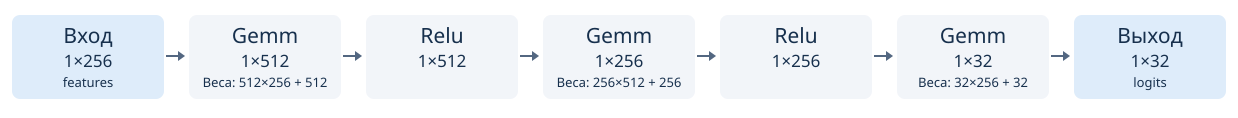

In [29]:
graph_path = OUT / "onnx-graph.svg"
if not REPLAY:
    draw_onnx_chain(describe_onnx_chain(graph), graph_path)
if graph_path.is_file():
    display(SVG(filename=str(graph_path)))
else:
    print("Схема ONNX появится после запуска экспорта в этой версии ноутбука.")

### Выполняем тот же граф в ONNX Runtime

Проверенный файл уже можно открыть в сессии ONNX Runtime. Сначала выберем исполнителя, затем передадим ему те же восемь входов, что и исходной модели PyTorch.

In [30]:
def check_logits(predict):
    '''Сверяет оценки и метки движка с PyTorch на восьми входах.'''
    max_error = 0.0
    with torch.inference_mode():
        for item in test_inputs.split(1):
            expected = model_cpu(item)
            actual = predict(item).cpu()
            torch.testing.assert_close(actual, expected, rtol=1e-4, atol=1e-5)
            torch.testing.assert_close(actual.argmax(1), expected.argmax(1))
            max_error = max(max_error, (actual - expected).abs().max().item())
    return max_error

In [31]:
def make_ort_session(profiling=False):
    '''Открывает ONNX для выбранного устройства и фиксирует настройки FP32.'''
    options = ort.SessionOptions()
    options.intra_op_num_threads = 1
    options.enable_profiling = profiling
    options.profile_file_prefix = str(OUT / "ort")
    if not profiling:
        options.optimized_model_filepath = str(OUT / "classifier.ort.onnx")
    providers = ["CPUExecutionProvider"]
    if USE_CUDA:
        # ORT и PyTorch используют один поток: перенос входа завершится до чтения.
        stream = torch.cuda.current_stream(DEVICE)
        cuda_options = {"device_id": "0", "use_tf32": "0", "user_compute_stream": str(stream.cuda_stream)}
        providers.insert(0, ("CUDAExecutionProvider", cuda_options))
    session = ort.InferenceSession(str(ONNX_PATH), sess_options=options, providers=providers)

    if USE_CUDA and "CUDAExecutionProvider" not in session.get_providers():
        raise RuntimeError("ORT не загрузил CUDAExecutionProvider. Проверьте CUDA и cuDNN.")
    return session

На GPU привяжем тензоры PyTorch к входу и выходу сессии. Так можно замерить вычисление с готовым входом на устройстве. Для полного запроса добавим копирование.

In [32]:
def ort_on_device(session):
    '''Привязывает тензоры PyTorch как вход и выход ONNX Runtime.'''
    if not USE_CUDA:
        def predict(x):
            logits = session.run([OUTPUT], {INPUT: x.numpy()})[0]
            return torch.from_numpy(logits)
        return predict

    binding = session.io_binding()
    output = torch.empty((1, CLASSES), device=DEVICE)
    binding.bind_output(OUTPUT, "cuda", 0, np.float32, tuple(output.shape), output.data_ptr())

    def predict(x):
        binding.bind_input(INPUT, "cuda", 0, np.float32, tuple(x.shape), x.data_ptr())
        session.run_with_iobinding(binding)
        return output

    return predict

In [33]:
if not REPLAY:
    session = make_ort_session()
    ort_predict = ort_on_device(session)
    row = measure_torch(f"ONNX Runtime ({DEVICE.type.upper()})", ort_predict, torch.inference_mode)
    row["max_error"] = check_logits(lambda x: ort_predict(x.to(DEVICE)))
    row["version"] = ort.__version__
    save_json("ort.json", row)

Список провайдеров показывает, какие исполнители подключены. Чтобы найти исполнителя каждой операции, запишем один вызов в отдельной сессии с профилированием.

In [34]:
if not REPLAY:
    traced_session = make_ort_session(profiling=True)
    ort_on_device(traced_session)(x_device)
    trace_name = Path(traced_session.end_profiling()).name
    events = read_json(trace_name)
    placements = sorted({
        (event["name"], event["args"]["provider"])
        for event in events
        if event.get("cat") == "Node" and event.get("args", {}).get("provider")
    })
    save_json("ort-profile.json", {"trace": trace_name, "placements": placements})

print(read_json("ort-profile.json"))

{'trace': 'ort_2026-11-18_15-03-46_813.json', 'placements': [['node_linear_1_kernel_time', 'CUDAExecutionProvider'], ['node_linear_2_kernel_time', 'CUDAExecutionProvider'], ['node_linear_kernel_time', 'CUDAExecutionProvider'], ['node_relu_1_kernel_time', 'CUDAExecutionProvider'], ['node_relu_kernel_time', 'CUDAExecutionProvider']]}


In [35]:
# @title Посмотреть, в каком порядке ONNX Runtime выполнил узлы
show_trace(OUT / read_json("ort-profile.json")["trace"])

### Сверяем исходный и оптимизированный графы

В профиле ONNX Runtime можно увидеть узлы, имён которых не было в исходном файле. Сессия может объединить линейный слой и активацию в `FusedGemm`. Сравним списки операций обоих графов и посмотрим, произошло ли это в нашем запуске.

In [36]:
def onnx_operations(model_path):
    """Возвращает названия операций и встроенные активации из ONNX-файла."""
    model = onnx.load(model_path)
    operations = []
    for node in model.graph.node:
        name = f"{node.domain}::{node.op_type}" if node.domain else node.op_type
        activation = next((attr.s.decode() for attr in node.attribute if attr.name == "activation"), "")
        operations.append(f"{name} [{activation}]" if activation else name)
    return operations

In [37]:
if not REPLAY:
    save_json("ort-graphs.json", {
        "Экспорт PyTorch": onnx_operations(ONNX_PATH),
        "Граф сессии ONNX Runtime": onnx_operations(OUT / "classifier.ort.onnx"),
    })

if (OUT / "ort-graphs.json").is_file():
    graphs = read_json("ort-graphs.json")
    show_table(
        ["Версия графа", "Узлов", "Операции в порядке файла"],
        [(name, len(ops), " → ".join(ops)) for name, ops in graphs.items()],
    )

| Версия графа | Узлов | Операции в порядке файла |
| --- | --- | --- |
| Экспорт PyTorch | 5 | Gemm → Relu → Gemm → Relu → Gemm |
| Граф сессии ONNX Runtime | 5 | Gemm → Relu → Gemm → Relu → Gemm |

### Собираем движок TensorRT

ONNX Runtime подготовил граф для своей сессии. TensorRT возьмёт исходный ONNX и соберёт из него файл `classifier.plan` для NVIDIA GPU. Зафиксируем время сборки отдельно от времени прогноза.

In [38]:
def build_engine():
    '''Разбирает ONNX и сохраняет движок TensorRT для текущего GPU.'''
    start = perf_counter()
    builder = trt.Builder(logger)
    network = builder.create_network()
    parser = trt.OnnxParser(network, logger)
    if not parser.parse_from_file(str(ONNX_PATH)):
        errors = [str(parser.get_error(i)) for i in range(parser.num_errors)]
        raise RuntimeError("\n".join(errors))
    config = builder.create_builder_config()
    config.clear_flag(trt.BuilderFlag.TF32)
    config.profiling_verbosity = trt.ProfilingVerbosity.DETAILED
    plan = builder.build_serialized_network(network, config)
    if plan is None:
        raise RuntimeError("TensorRT не собрал движок.")
    engine_path = OUT / "classifier.plan"
    engine_path.write_bytes(bytes(plan))
    return engine_path, (perf_counter() - start) * 1000

In [39]:
if TRT_ENABLED:
    logger = trt.Logger(trt.Logger.WARNING)
    engine_path, build_ms = build_engine()
    runtime = trt.Runtime(logger)
    engine = runtime.deserialize_cuda_engine(engine_path.read_bytes())
    if engine is None:
        raise RuntimeError("TensorRT не загрузил движок.")
    trt_context = engine.create_execution_context()
    if trt_context is None:
        raise RuntimeError("TensorRT не создал контекст выполнения.")
    trt_output = torch.empty((1, CLASSES), device=DEVICE)
    if not trt_context.set_tensor_address(OUTPUT, trt_output.data_ptr()):
        raise RuntimeError("TensorRT отклонил адрес выхода.")

После загрузки движка передадим ему адрес входного тензора и запустим вычисления в потоке CUDA PyTorch. Затем сверим логиты и метки и применим тот же таймер, что в предыдущих запусках.

In [40]:
def tensor_rt_predict(x):
    '''Запускает движок в текущем потоке CUDA PyTorch.'''
    if not trt_context.set_tensor_address(INPUT, x.data_ptr()):
        raise RuntimeError("TensorRT отклонил адрес входа.")
    stream = torch.cuda.current_stream(DEVICE)
    if not trt_context.execute_async_v3(stream.cuda_stream):
        raise RuntimeError("Ошибка запуска TensorRT.")
    return trt_output


if TRT_ENABLED:
    row = measure_torch("TensorRT", tensor_rt_predict, torch.inference_mode)
    row["max_error"] = check_logits(lambda x: tensor_rt_predict(x.to(DEVICE)))
    row["prep_ms"] = build_ms
    row["version"] = trt.__version__
    save_json("trt.json", row)

Сохраним трассу полного запроса. На ней видны перенос входа, исполнение движка и возврат класса. Если доступен `trtexec`, отдельно запишем его отчёт.

In [41]:
if TRT_ENABLED:
    with torch.inference_mode():
        summary = save_trace("tensorrt-request.json", lambda: tensor_rt_predict(
            x_cpu.to(DEVICE)
        ).argmax(dim=1).cpu())
    save_json("trt-profile.json", summary)

In [42]:
if TRT_ENABLED:
    # trtexec доступен, если установлен дистрибутив TensorRT с CLI.
    trtexec = shutil.which("trtexec")
    if trtexec:
        with (OUT / "trtexec.log").open("w") as log:
            result = subprocess.run([
                trtexec, f"--loadEngine={engine_path}", "--dumpProfile",
                "--warmUp=200", "--duration=1", "--dumpLayerInfo",
            ], stdout=log, stderr=subprocess.STDOUT, timeout=120)
        print("Лог trtexec:", OUT / "trtexec.log", "код завершения:", result.returncode)

In [43]:
if (OUT / "trt-profile.json").is_file():
    print(read_json("trt-profile.json"))
else:
    print("Профиль TensorRT появится после прогона движка на NVIDIA GPU.")

Профиль TensorRT появится после прогона движка на NVIDIA GPU.


In [44]:
# @title Проследить полный запрос TensorRT
if (OUT / "tensorrt-request.json").is_file():
    show_trace(OUT / "tensorrt-request.json")

### Разбираем слои движка

По полной трассе видно, когда движок занял GPU. Чтобы понять, что он выполнял внутри, прочитаем слои через Engine Inspector. Затем отдельно измерим время каждого слоя и сопоставим имена из профиля с метаданными движка.

In [45]:
def inspect_engine():
    """Сохраняет описание слоёв и читает формы входа и выхода движка."""
    inspector = engine.create_engine_inspector()
    details = inspector.get_engine_information(trt.LayerInformationFormat.JSON)
    (OUT / "engine-inspector.json").write_text(details, encoding="utf-8")
    tensors = [
        {"name": name,
         "dtype": str(engine.get_tensor_dtype(name)).rsplit(".", 1)[-1],
         "shape": "×".join(map(str, engine.get_tensor_shape(name)))}
        for name in (INPUT, OUTPUT)
    ]
    return json.loads(details)["Layers"], tensors

In [46]:
import re
from collections import defaultdict
from statistics import median


def profile_trt_layers():
    """Снимает десять измерений для каждого слоя в отдельном прогоне."""
    class LayerProfiler(trt.IProfiler):
        def __init__(self):
            super().__init__()
            self.samples = defaultdict(list)

        def report_layer_time(self, layer_name, ms):
            """Получает измерение слоя от TensorRT."""
            self.samples[layer_name].append(float(ms))

    profiler = LayerProfiler()
    trt_context.profiler = profiler
    with torch.inference_mode():
        for _ in range(10):
            tensor_rt_predict(x_device)
            wait_for_gpu()
    return profiler.samples

In [47]:
def summarize_layers(engine_layers, layer_samples):
    """Сопоставляет слои движка, исходные узлы и медианное время."""

    layers = []
    for layer in engine_layers:
        name = layer["Name"]
        metadata = layer.get("Metadata") or ""
        sources = re.findall(r"\[ONNX Layer: ([^\]]+)\]", str(metadata))
        samples = layer_samples.get(name)
        layers.append({
            "name": name,
            "type": layer.get("LayerType", "—"),
            "onnx_nodes": ", ".join(sources),
            "tactic": layer.get("TacticName") or "—",
            "median_ms": median(samples) if samples else None,
        })
    return layers

В итоговой таблице для движка покажем формы, слои и медианное время. Если TensorRT сохранил имена исходных узлов, по ним можно вернуться к схеме ONNX.

In [48]:
if TRT_ENABLED:
    engine_layers, tensors = inspect_engine()
    save_json("engine-layers.json", {
        "tensors": tensors,
        "layers": summarize_layers(engine_layers, profile_trt_layers()),
    })

In [49]:
if (OUT / "engine-layers.json").is_file():
    info = read_json("engine-layers.json")
    show_table(["Тензор", "Тип", "Форма"], [(t["name"], t["dtype"], t["shape"]) for t in info["tensors"]])
    show_table(
        ["Слой движка", "Тип", "Узлы ONNX из метаданных", "Медиана, мс"],
        [
            (layer["name"], layer["type"], layer["onnx_nodes"] or "—",
             f"{layer['median_ms']:.4f}" if layer["median_ms"] is not None else "—")
            for layer in info["layers"]
        ],
    )
    sample = next((layer for layer in info["layers"] if layer["tactic"] != "—"), None)
    if sample:
        print("Пример выбранной реализации слоя")
        print(sample["name"], "→", sample["tactic"])
    print("Полный отчёт с тактиками и форматами тензоров: engine-inspector.json.")
else:
    print("Таблица слоёв появится после прогона TensorRT на GPU.")

Таблица слоёв появится после прогона TensorRT на GPU.


Послойный профиль объясняет время внутри движка. В конце сопоставим его с замером полного запроса, в который также входят копирование и получение метки.

## 4. Генерация текста под нагрузкой

Классификатор возвращал ответ за один проход. Языковая модель обрабатывает промпт на этапе prefill и продолжает выдавать токены по мере генерации. Поэтому для сервера важны и время до первого токена, и общий выпуск токенов в секунду.

Возьмём Qwen3-0.6B в FP16. В каждом прогоне подадим 96 запросов по 256 входных и 32 выходных токена. Отправим синтетические входы на `/v1/completions`, минуя чат-шаблон Qwen3. При фиксированных длинах и seed сравним скорость генерации в трёх режимах сервера.

### vLLM меняет состав группы на каждом шаге

На первом шаге в группе A и B. B завершился, а A продолжает генерацию. На следующем шаге планировщик добавляет к A запрос C из очереди.

Так работает continuous batching. Состав группы можно менять, пока предыдущие запросы продолжают генерацию. В замерах ниже сравним один и восемь запросов в полёте. Посмотрим, как изменятся задержка первого токена и общий выпуск токенов.

### SGLang переиспользует вычисления для общего начала

У двух запросов одинаковое начало P и разные продолжения, X и Y. Если кеш сохранился, второй запрос использует готовые вычисления для P.

RadixAttention ищет совпадающее начало в дереве префиксов. vLLM тоже поддерживает повторное использование префиксов. В нашем замере отключим эту настройку, чтобы сравнивать режимы исполнения на одинаковой нагрузке.

### Сколько токенов можно выдать за один проход?

Продолжим промпт «Положи книгу». В примере каждое слово и знак препинания считаем отдельным токеном. При жадной генерации модель всегда выбирает самый вероятный следующий токен. Для наглядности зададим её выбор короткой таблицей: после «книгу» она выбирает «на», после «на» — «стол».

In [50]:
# В этой учебной модели следующий токен зависит только от предыдущего.
next_token = {"книгу": "на", "на": "стол", "стол": ".", "пол": "!", "!": "."}
prompt_tail = "книгу"
draft = ["на", "пол", "!"]

# Каждая позиция известного черновика становится входом для следующего предсказания.
predictions = [next_token[token] for token in [prompt_tail, *draft]]
print("Черновик:", draft)
print("Выбор основной модели по позициям:", predictions)

Черновик: ['на', 'пол', '!']
Выбор основной модели по позициям: ['на', 'стол', '!', '.']


Первая позиция совпала. Во второй основная модель выбрала «стол». Даже если третий токен совпадёт, его проверяли после слова «пол». Для продолжения «на стол» это предсказание уже не годится.

In [51]:
def verify_greedy(draft, predictions):
    """Возвращает принятый префикс и один токен основной модели."""
    for i, token in enumerate(draft):
        if token != predictions[i]:
            return draft[:i], predictions[i]
    return draft.copy(), predictions[len(draft)]  # Весь черновик совпал.


accepted, extra = verify_greedy(draft, predictions)
print("Принято из черновика:", accepted)
print("Выдано за проход:", [*accepted, extra])
print("Следующий токен после исправления:", next_token[extra])

Принято из черновика: ['на']
Выдано за проход: ['на', 'стол']
Следующий токен после исправления: .


За одну проверку получили «на стол». Точку модель выберет следующим шагом. Если все предложения совпадут, за тот же проход можно выдать весь черновик и ещё один токен. Здесь мы проследили решения по позициям. В трансформере оценки этих позиций вычисляются параллельно за один проход с причинной маской.

Для замера в vLLM включим вариант с поиском повторов. Он ищет в контексте уже встречавшуюся цепочку токенов и берёт её продолжение как черновик. Вторую модель для этого загружать не нужно.

In [52]:
from contextlib import contextmanager
import signal
import socket
import time
from urllib.error import URLError
from urllib.request import urlopen

LLM = "Qwen/Qwen3-0.6B"
PROMPTS = 96

def available_port():
    '''Выбирает свободный порт для локального демо-сервера.'''
    with socket.socket() as listener:
        listener.bind(("127.0.0.1", 0))
        return listener.getsockname()[1]

Запустим одну модель в трёх режимах: eager, стандартный и стандартный с черновиком. Во всех трёх отключим кеш общих префиксов и сохраним одинаковые длины запросов.

In [53]:
def server_command(port, extra_args, profile_dir):
    """Готовит команду сервера с одним набором параметров модели."""

    command = [
        str(VLLM_EXE), "serve", LLM,
        "--host", "127.0.0.1", "--port", str(port),
        "--dtype", "float16", "--max-model-len", "512",
        "--gpu-memory-utilization", "0.5", "--no-enable-prefix-caching",
        *extra_args,
    ]
    if profile_dir is not None:
        command += ["--profiler-config", json.dumps({
            "profiler": "torch", "torch_profiler_dir": str(profile_dir),
            "torch_profiler_with_stack": False,
        })]
    return command

In [54]:
def wait_for_server(server, base_url, log_path):
    """Ждёт ответа от /health или показывает лог запуска."""

    deadline = time.monotonic() + 600
    while time.monotonic() < deadline and server.poll() is None:
        try:
            with urlopen(base_url + "/health", timeout=2) as response:
                if response.status == 200:
                    break
        except (URLError, TimeoutError):
            time.sleep(1)
    else:
        tail = "\n".join(log_path.read_text(errors="replace").splitlines()[-12:])
        raise RuntimeError(f"vLLM не запустился. {log_path}\n{tail}")

In [55]:
def stop_server(server):
    """Останавливает сервер и его GPU-воркеры."""

    # В отдельной группе находится сервер и его GPU-воркеры.
    try:
        os.killpg(server.pid, signal.SIGTERM)
    except ProcessLookupError:
        pass
    try:
        server.wait(timeout=30)
    except subprocess.TimeoutExpired:
        os.killpg(server.pid, signal.SIGKILL)
        server.wait()

In [56]:
@contextmanager
def llm_server(mode, extra_args, profile_dir=None):
    """Запускает сервер, ждёт готовности и освобождает GPU после прогона."""
    port = available_port()
    base_url = f"http://127.0.0.1:{port}"
    command = server_command(port, extra_args, profile_dir)
    log_path = OUT / f"server-{mode}.log"
    with log_path.open("w") as log:
        server = subprocess.Popen(
            command, stdout=log, stderr=subprocess.STDOUT, start_new_session=True
        )
        try:
            wait_for_server(server, base_url, log_path)
            yield base_url
        finally:
            stop_server(server)

Когда сервер готов, клиент отправляет один и тот же набор запросов. Для каждого режима проведём два замера: при одном и при восьми запросах в полёте.

In [57]:
def benchmark_command(base_url, concurrency, profiling, filename):
    """Задаёт длины запросов, нагрузку и способ записи результата."""

    command = [
        str(VLLM_EXE), "bench", "serve",
        "--base-url", base_url, "--backend", "openai", "--endpoint", "/v1/completions",
        "--model", LLM, "--dataset-name", "random", "--seed", "42",
        "--random-input-len", "256", "--random-output-len", "32", "--random-range-ratio", "0",
        "--ignore-eos", "--temperature", "0",
        "--max-concurrency", str(concurrency), "--num-prompts", str(8 if profiling else PROMPTS),
        "--num-warmups", "8",
        "--percentile-metrics", "ttft,tpot", "--metric-percentiles", "95",
    ]
    if profiling:
        command.append("--profile")
    else:
        command += ["--save-result", "--result-dir", str(OUT), "--result-filename", filename]
    return command

In [58]:
def read_vllm_result(filename, log_name, mode, concurrency):
    """Проверяет, что все запросы завершились, и выбирает метрики для таблицы."""

    result = read_json(filename)
    if result["completed"] != PROMPTS or result.get("failed", 0):
        raise RuntimeError(f"Часть запросов не завершилась. См. {log_name}.")
    return {
        "mode": mode,
        "concurrency": concurrency,
        "ttft": result["p95_ttft_ms"],
        "tpot": result["p95_tpot_ms"],
        "output_rate": result["output_throughput"],
    }

In [59]:
def bench_vllm(base_url, mode, concurrency, profiling=False):
    """Запускает клиент и сохраняет лог. Замеры читает из JSON."""
    filename = f"vllm-{mode}-{concurrency}.json"
    command = benchmark_command(base_url, concurrency, profiling, filename)
    suffix = "-profile.log" if profiling else ".log"
    log_name = filename.removesuffix(".json") + suffix
    with (OUT / log_name).open("w") as log:
        subprocess.run(command, stdout=log, stderr=subprocess.STDOUT, check=True, timeout=600)
    if not profiling:
        return read_vllm_result(filename, log_name, mode, concurrency)

In [60]:
# Ищем совпадающие цепочки длиной до четырёх токенов и предлагаем до трёх следующих.
spec_config = {"method": "ngram", "prompt_lookup_max": 4, "num_speculative_tokens": 3}
modes = [
    ("eager", ["--enforce-eager"]),
    ("default", []),
    ("ngram", ["--speculative-config", json.dumps(spec_config)]),
]

In [61]:
if not REPLAY and RUN_VLLM and USE_CUDA:
    if not VLLM_EXE.is_file():
        print("vLLM не найден. Запустите ячейку установки или укажите путь в VLLM_EXE.")
    else:
        # vLLM запускаем после замеров классификатора, чтобы он не влиял на них.
        rows = []
        version = subprocess.check_output([str(VLLM_EXE), "--version"], text=True).strip()
        save_json("vllm-environment.json", {"version": version, "model": LLM, "prompts": PROMPTS})
        for mode, flags in modes:
            with llm_server(mode, flags) as base_url:
                for concurrency in (1, 8):
                    print(f"vLLM {mode}, запросов в полёте: {concurrency}", flush=True)
                    rows.append(bench_vllm(base_url, mode, concurrency))
                    save_json("vllm.json", rows)

vLLM eager, запросов в полёте: 1
vLLM eager, запросов в полёте: 8
vLLM default, запросов в полёте: 1
vLLM default, запросов в полёте: 8
vLLM ngram, запросов в полёте: 1
vLLM ngram, запросов в полёте: 8


Снимем трассу отдельным запуском на восьми одновременных запросах. Время работы профилировщика тогда не попадёт в таблицу задержек.

In [62]:
if not REPLAY and RUN_VLLM and USE_CUDA and VLLM_EXE.is_file() and PROFILE_VLLM:
    with llm_server("profile", [], profile_dir=OUT / "vllm-trace") as base_url:
        bench_vllm(base_url, "profile", concurrency=8, profiling=True)

На временной шкале одного процесса vLLM сопоставим работу CPU с участками, где занят GPU. Если профилировщик записал несколько файлов, ячейка перечислит их по номерам. Для первого просмотра выберем трассу GPU-воркера, если он указан в имени файла.

In [63]:
# @title Открыть трассу vLLM
worker_index = 0  # @param {type:"integer"}
trace_dir = OUT / "vllm-trace"
traces = sorted(
    [*trace_dir.rglob("*.json"), *trace_dir.rglob("*.json.gz")],
    key=lambda path: ("worker" not in path.name.lower(), str(path)),
)
for index, path in enumerate(traces):
    print(index, path.relative_to(trace_dir))
if 0 <= worker_index < len(traces):
    show_trace(traces[worker_index])
elif traces:
    print("Выберите номер из списка выше.")
else:
    print("Трасса появится после прогона vLLM с PROFILE_VLLM на GPU.")

0 226adf25280e_6858.async_llm.1795015174284748452.pt.trace.json.gz
1 rank0.1795015174556308720.pt.trace.json.gz


## 5. Сводка замеров и вывод

Сначала вернёмся к классификатору. Сопоставим p95 до готовых логитов с p95 полного вызова. Если быстрее стали только логиты, по трассе можно проверить, какую часть времени по-прежнему занимают копирование и выбор класса.

In [64]:
classifier_rows = read_json("torch.json")
for filename in ("ort.json", "trt.json"):
    if (OUT / filename).is_file():
        classifier_rows.append(read_json(filename))

recorded_cuda = read_json("environment.json")["cuda"] is not None
boundary = "GPU → GPU" if recorded_cuda else "CPU → CPU"
show_table(
    ["Классификатор", f"Логиты {boundary}, p50 / p95, мс",
     "CPU → метка на CPU, p95, мс", "Первый вызов compile / сборка TRT, мс"],
    [
        (row["name"], f"{row['logits']['p50']:.4f} / {row['logits']['p95']:.4f}",
         f"{row['request']['p95']:.4f}",
         f"{row['prep_ms']:.1f}" if "prep_ms" in row else "—")
        for row in classifier_rows
    ],
)
for row in classifier_rows:
    if "max_error" in row:
        print(f"{row['name']} {row['version']}: метки совпали, "
              f"максимальная ошибка логитов {row['max_error']:.2g}.")

| Классификатор | Логиты GPU → GPU, p50 / p95, мс | CPU → метка на CPU, p95, мс | Первый вызов compile / сборка TRT, мс |
| --- | --- | --- | --- |
| PyTorch eager | 0.3750 / 0.5529 | 1.7903 | — |
| PyTorch eager + no_grad | 0.2551 / 0.3444 | 0.3741 | — |
| PyTorch eager + inference_mode | 0.1647 / 0.1905 | 0.5922 | — |
| torch.compile + inference_mode | 0.2687 / 0.3689 | 0.5393 | 22215.5 |
| ONNX Runtime (CUDA) | 0.1268 / 0.2641 | 0.3603 | — |

ONNX Runtime (CUDA) 1.27.0: метки совпали, максимальная ошибка логитов 5.8e-08.


Для генерации сравним время до первого токена (TTFT), среднее время на токен после первого (TPOT) и общий выпуск токенов в секунду. Для TTFT и TPOT покажем 95-й процентиль по запросам.

In [65]:
vllm_rows = read_json("vllm.json") if (OUT / "vllm.json").is_file() else []
if vllm_rows:
    print(read_json("vllm-environment.json"))
    show_table(
        ["vLLM", "Запросов в полёте", "TTFT p95, мс", "TPOT p95, мс/токен", "Выходных токенов/с"],
        [(r["mode"], r["concurrency"], f"{r['ttft']:.2f}", f"{r['tpot']:.2f}",
          f"{r['output_rate']:.1f}") for r in vllm_rows],
    )
else:
    print("В этом каталоге пока нет замеров vLLM.")

{'version': '0.31.0', 'model': 'Qwen/Qwen3-0.6B', 'prompts': 96}


| vLLM | Запросов в полёте | TTFT p95, мс | TPOT p95, мс/токен | Выходных токенов/с |
| --- | --- | --- | --- | --- |
| eager | 1 | 121.50 | 48.32 | 24.0 |
| eager | 8 | 301.59 | 50.51 | 169.8 |
| default | 1 | 49.00 | 7.79 | 113.3 |
| default | 8 | 253.63 | 17.05 | 414.9 |
| ngram | 1 | 40.66 | 22.80 | 81.6 |
| ngram | 8 | 230.46 | 31.11 | 386.3 |

Сверим p95 полного вызова с базовым режимом PyTorch. Для vLLM посмотрим, как рост нагрузки изменил ожидание первого токена.

In [66]:
baseline = next(row for row in classifier_rows if row["name"] == "PyTorch eager + inference_mode")
lines = []
for row in classifier_rows:
    if row is baseline or row["name"] in {"PyTorch eager", "PyTorch eager + no_grad"}:
        continue
    logits_ratio = baseline["logits"]["p95"] / row["logits"]["p95"]
    request_ratio = baseline["request"]["p95"] / row["request"]["p95"]
    lines.append(f"- **{row['name']}**. Отношение времени PyTorch eager с "
                 f"`inference_mode()` ко времени этого режима: {logits_ratio:.2f}× по p95 до логитов "
                 f"и {request_ratio:.2f}× по p95 полного вызова.")

for mode in ("eager", "default"):
    runs = {row["concurrency"]: row for row in vllm_rows if row["mode"] == mode}
    if 1 in runs and 8 in runs:
        single, parallel = runs[1], runs[8]
        lines.append(f"- **vLLM {mode} при переходе с 1 на 8 запросов**. "
                     f"TTFT p95: {single['ttft']:.2f} → {parallel['ttft']:.2f} мс. "
                     f"Скорость: {single['output_rate']:.1f} → {parallel['output_rate']:.1f} токенов/с.")

display(Markdown("\n".join(lines) if lines else "Сравнение появится после запуска движков."))

- **torch.compile + inference_mode**. Отношение времени PyTorch eager с `inference_mode()` ко времени этого режима: 0.52× по p95 до логитов и 1.10× по p95 полного вызова.
- **ONNX Runtime (CUDA)**. Отношение времени PyTorch eager с `inference_mode()` ко времени этого режима: 0.72× по p95 до логитов и 1.64× по p95 полного вызова.
- **vLLM eager при переходе с 1 на 8 запросов**. TTFT p95: 121.50 → 301.59 мс. Скорость: 24.0 → 169.8 токенов/с.
- **vLLM default при переходе с 1 на 8 запросов**. TTFT p95: 49.00 → 253.63 мс. Скорость: 113.3 → 414.9 токенов/с.

In [67]:
for concurrency in (1, 8):
    runs = {row["mode"]: row for row in vllm_rows if row["concurrency"] == concurrency}
    if "default" in runs and "ngram" in runs:
        before, after = runs["default"]["tpot"], runs["ngram"]["tpot"]
        print(f"Запросов в полёте: {concurrency}. Время на токен (p95): "
              f"{before:.2f} мс без черновика и {after:.2f} мс с черновиком.")

Запросов в полёте: 1. Время на токен (p95): 7.79 мс без черновика и 22.80 мс с черновиком.
Запросов в полёте: 8. Время на токен (p95): 17.05 мс без черновика и 31.11 мс с черновиком.


Для vLLM сначала отберём конфигурации, которые укладываются в допустимое время до первого токена. Среди них сравним число токенов в секунду. Сравнивайте строки default и ngram при одинаковом числе запросов. На случайных входных токенах повторов может быть мало. Если время на токен выросло, расходы на черновик и проверку в этом прогоне не окупились.

Последняя ячейка соберёт замеры и профили в архив. Для показа распакуйте его и укажите каталог в `REPLAY_DIR`.

In [68]:
if not REPLAY:
    # Архив лежит рядом с каталогом и содержит уже снятые профили и числа.
    archive = shutil.make_archive(str(OUT), "zip", root_dir=OUT.parent, base_dir=OUT.name)
    print("Архив показа:", archive)

Архив показа: /content/inference-demo/20261118-150255-373120.zip


### Документация

- [PyTorch Profiler](https://docs.pytorch.org/tutorials/recipes/recipes/profiler_recipe.html)
- [torch.compile](https://docs.pytorch.org/tutorials/intermediate/torch_compile_tutorial)
- [ONNX Runtime I/O Binding](https://onnxruntime.ai/docs/performance/tune-performance/iobinding.html)
- [TensorRT Runtime API](https://docs.nvidia.com/deeplearning/tensorrt/latest/inference-library/python-api-docs.html)
- [Бенчмарк vLLM](https://docs.vllm.ai/en/v0.31.0/cli/bench/serve/)
- [Профилирование vLLM](https://docs.vllm.ai/en/stable/contributing/profiling/)
- [Оптимизации графа в ONNX Runtime](https://onnxruntime.ai/docs/performance/graph-optimizations)
- [TensorRT Engine Inspector](https://docs.nvidia.com/deeplearning/tensorrt/10.x.x/inference-library/engine-tools.html)
- [Speculative decoding и правило проверки](https://proceedings.mlr.press/v202/leviathan23a.html)
- [Поиск черновика по n-граммам в vLLM](https://github.com/vllm-project/vllm/blob/v0.31.0/docs/features/speculative_decoding/n_gram.md)
- [Карточка Qwen3-0.6B](https://huggingface.co/Qwen/Qwen3-0.6B)
- [Просмотр трасс в VizTracer](https://github.com/gaogaotiantian/viztracer)